In [ ]:


import numpy as np
import pandas as pd

In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torch.utils.data import DataLoader, Dataset, random_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support
import timm
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [ ]:
!pip install patool
import patoolib

patoolib.extract_archive("btp_dataset_real.zip")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.5/86.5 kB 2.2 MB/s eta 0:00:00


INFO patool: Extracting btp_dataset_real.zip ...
INFO:patool:Extracting btp_dataset_real.zip ...
INFO patool: running /usr/bin/7z x -aou -o./Unpack_vfspmtqz -- btp_dataset_real.zip
INFO:patool:running /usr/bin/7z x -aou -o./Unpack_vfspmtqz -- btp_dataset_real.zip
INFO patool: ... btp_dataset_real.zip extracted to `btp_dataset'.
INFO:patool:... btp_dataset_real.zip extracted to `btp_dataset'.


'btp_dataset'

In [ ]:


import shutil
import os

# Define source and destination folders
source_folder = "/content/btp_dataset/hypodontia"  # Replace with the actual path to your "ulcers" folder
destination_folder = "/content/btp_dataset_new/hypodontia"  # Replace with the actual path to your "hypodontia" folder


if not os.path.exists(destination_folder):
    os.makedirs(destination_folder)

# Initialize a counter for moved images
moved_count = 0

# Iterate through files in the source folder
for filename in os.listdir(source_folder):
    source_path = os.path.join(source_folder, filename)
    destination_path = os.path.join(destination_folder, filename)

    # Check if the item is a file (not a subdirectory)
    if os.path.isfile(source_path):
      try:
          # Move the file
          shutil.move(source_path, destination_path)
          moved_count += 1

          # Break the loop after moving 1637 images
          if moved_count == 1637:
              print(f"Moved {moved_count} images from '{source_folder}' to '{destination_folder}'.")
              break
      except Exception as e:
          print(f"Error moving {filename}: {e}")

# Print a message if fewer than 1637 images were found
if moved_count < 1637:
    print(f"Only {moved_count} images were found in '{source_folder}'.")

Moved 1637 images from '/content/btp_dataset/hypodontia' to '/content/btp_dataset_new/hypodontia'.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# input folder
from pathlib import Path
Path('/content/btp_dataset').mkdir(parents=True, exist_ok=True)

In [ ]:
import shutil
import os

# Caries.
# The source path
caries_file_path = Path('/content/btp_dataset/caries')

# The destination path
caries_new_directory = Path('/content/btp_dataset_new/caries')

# Copying data from input folder to working folder
shutil.copytree(caries_file_path, caries_new_directory)

PosixPath('/content/btp_dataset_new/caries')

In [ ]:
# Calculus
# The source path
calculus_file_path = Path('/content/btp_dataset/Calculus')
# The destination path
calculus_new_directory = Path('/content/btp_dataset_new/calculus')
# Copying data from input folder to working folder
shutil.copytree(calculus_file_path, calculus_new_directory)

#Gingivitis
# The source path
gingivitis_file_path = Path('/content/btp_dataset/Gingivitis')
# The destination path
gingivitis_new_directory = Path('/content/btp_dataset_new/gingivitis')
# Copying data from input folder to working folder
shutil.copytree(gingivitis_file_path, gingivitis_new_directory)

#Ulcers
# The source path
ulcer_file_path = Path('/content/btp_dataset/ulcer')
# The destination path
ulcer_new_directory = Path('/content/btp_dataset_new/ulcers')
# Copying data from input folder to working folder
shutil.copytree(ulcer_file_path, ulcer_new_directory)

#Tooth Discoloration
# The source path
toothDiscoloration_file_path = Path('/content/btp_dataset/discolouration')
# The destination path
toothDiscoloration_new_directory = Path('/content/btp_dataset_new/discolouration')
# Copying data from input folder to working folder
shutil.copytree(toothDiscoloration_file_path, toothDiscoloration_new_directory)

#hypodontia
# The source path
hypodontia_file_path = Path('/content/btp_dataset/hypodontia')
# The destination path
hypodontia_new_directory = Path('/content/btp_dataset_new/hypodontia')
# Copying data from input folder to working folder
shutil.copytree(hypodontia_file_path, hypodontia_new_directory)

FileExistsError: [Errno 17] File exists: '/content/btp_dataset_new/hypodontia'

In [ ]:
# The different classes we have from the folders
import os
build_dir = "/content/btp_dataset_new"
os.listdir(build_dir)
caries_dir = os.path.join(build_dir,'caries')
gingivitis_dir = os.path.join(build_dir,'gingivitis')
toothDiscoloration_dir = os.path.join(build_dir,'discolouration')
ulcers_dir = os.path.join(build_dir,'ulcers')
hypodontia_dir = os.path.join(build_dir,'hypodontia')
calculus_dir = os.path.join(build_dir,'calculus')
os.listdir(build_dir)

['caries', 'gingivitis', 'calculus', 'hypodontia', 'discolouration', 'ulcers']

In [ ]:
# Showing the total number of images from each class/folder
import pandas as pd

data = pd.DataFrame(data=[len(os.listdir(caries_dir)), len(os.listdir(gingivitis_dir)),
                   len(os.listdir(toothDiscoloration_dir)), len(os.listdir(ulcers_dir)),
                   len(os.listdir(hypodontia_dir)),
                   len(os.listdir(calculus_dir))], index=['Caries', 'gingivitis',
                                                                    'toothDiscoloration', 'ulcers',
                                                                    'hypodontia', 'calculus'],
              columns=['Total Images'])

In [ ]:
data.to_csv('data_distribution.csv')

In [ ]:
# Sample of caries
from PIL import Image
import matplotlib.pyplot as plt
cariesimg=Image.open("/content/btp_dataset_working/calculus/(10).jpg")
plt.imshow(cariesimg)

FileNotFoundError: [Errno 2] No such file or directory: '/content/btp_dataset_working/calculus/(10).jpg'

In [ ]:
categories = data.index
categories

values = data['Total Images']

<ipython-input-13-0480a1023270>:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  barplot = sns.barplot(x=categories, y=values, palette="viridis")


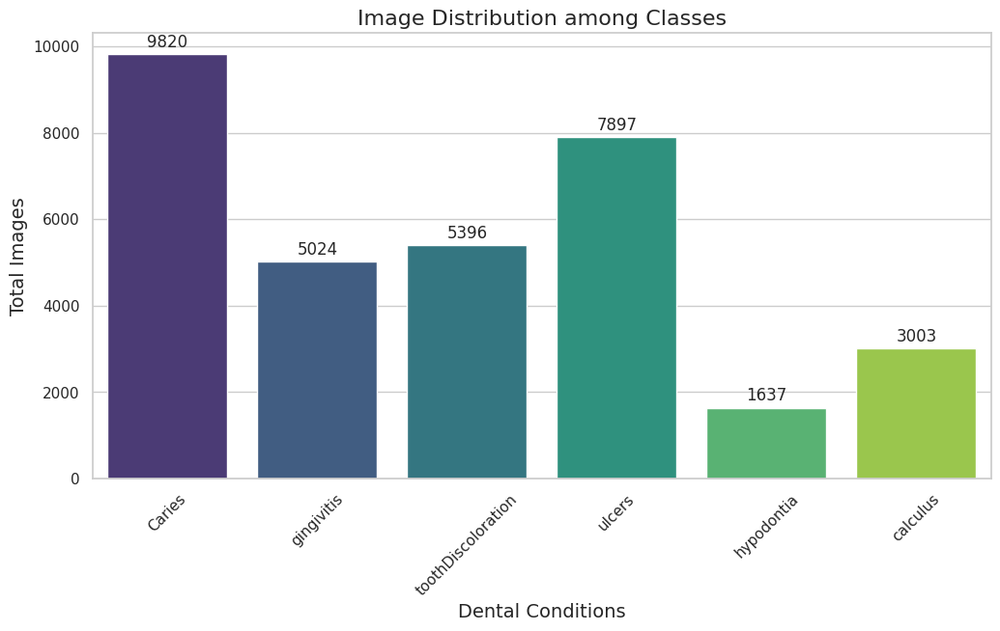

In [ ]:
import seaborn as sns

# Improved 2D bar plot
plt.figure(figsize=(12, 6))
sns.set(style="whitegrid")

# Creating the barplot
barplot = sns.barplot(x=categories, y=values, palette="viridis")

# Adding the text on the top of each bar
for p in barplot.patches:
    barplot.annotate(format(p.get_height(), '.0f'),
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha = 'center', va = 'center',
                     xytext = (0, 9),
                     textcoords = 'offset points')

# Setting titles and labels
plt.xlabel("Dental Conditions", fontsize=14)
plt.ylabel("Total Images", fontsize=14)
plt.title("Image Distribution among Classes", fontsize=16)
plt.xticks(rotation=45)
plt.savefig('imageDistribution.png')
plt.show()

In [ ]:
# Custom Dataset class
class OralDiseaseDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.classes = os.listdir(root_dir)
        self.data = []
        for cls in self.classes:
            path = os.path.join(root_dir, cls)
            for img_name in os.listdir(path):
                self.data.append((os.path.join(path, img_name), self.classes.index(cls)))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img_path, label = self.data[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

In [ ]:
import os
from PIL import Image
from torch.utils.data import Dataset

# Custom Dataset class
class OralDiseaseDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.classes = os.listdir(root_dir)
        self.class_to_idx = {cls: idx for idx, cls in enumerate(self.classes)}  # Mapping of class names to indices
        self.data = []

        # Collect all images with their paths and labels
        for cls in self.classes:
            class_path = os.path.join(root_dir, cls)
            for img_name in os.listdir(class_path):
                img_path = os.path.join(class_path, img_name)
                label = self.class_to_idx[cls]
                self.data.append({'path': img_path, 'label': label, 'class_name': cls})

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img_info = self.data[idx]
        img_path, label = img_info['path'], img_info['label']
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

    def get_data_info(self):
        """Returns a list of tuples with image path, label index, and class name."""
        return [(item['path'], item['label'], item['class_name']) for item in self.data]


In [ ]:
# Create dataset instance
root_dir="/content/btp_dataset_new"
dataset = OralDiseaseDataset(root_dir="/content/btp_dataset_new")

# Retrieve and print image paths and labels
data_info = dataset.get_data_info()
for path, label, class_name in data_info:
    print(f"Image Path: {path}, Label Index: {label}, Class Name: {class_name}")


Image Path: /content/btp_dataset_new/caries/caries_0_9932.jpeg, Label Index: 0, Class Name: caries
Image Path: /content/btp_dataset_new/caries/153_jpg.rf.724b451014d7d73bab371ffb03735898.jpg, Label Index: 0, Class Name: caries
Image Path: /content/btp_dataset_new/caries/caries_0_5729_jpeg.rf.bd5c343cc695dc97b885b78697ed7284.jpg, Label Index: 0, Class Name: caries
Image Path: /content/btp_dataset_new/caries/caries_0_2689_jpeg.rf.ab29c82ba1e4e7bb086084383bd7c073.jpg, Label Index: 0, Class Name: caries
Image Path: /content/btp_dataset_new/caries/caries_0_662_jpeg.rf.c21e279d102fb3a84e06760077c36f9d.jpg, Label Index: 0, Class Name: caries
Image Path: /content/btp_dataset_new/caries/caries_0_2226_jpeg.rf.45bf39b0a14be5623c5cd8838f3a0427.jpg, Label Index: 0, Class Name: caries
Image Path: /content/btp_dataset_new/caries/caries_0_7077_jpeg.rf.9d74aa5b5964395df61836f644187109.jpg, Label Index: 0, Class Name: caries
Image Path: /content/btp_dataset_new/caries/66_jpeg_jpg.rf.8ae0b5d37f7aad422c88

In [ ]:
import torch
import torch.nn as nn
import timm
from torchvision import transforms
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm

# Enhanced Dental Classification Model with Transformer Encoder
class EnhancedDentalClassifier(nn.Module):
    def __init__(self, num_classes, embed_dim=512, num_heads=8, num_transformer_layers=2):
        super(EnhancedDentalClassifier, self).__init__()

        # Base Model: MobileNetV2
        self.base_model = timm.create_model('mobilenetv2_100', pretrained=True, features_only=True)
        last_channel = self.base_model.feature_info[-1]['num_chs']  # Output channels of the last layer

        # Feature Pyramid Network (FPN)
        self.fpn = FeaturePyramidNetwork(last_channel)

        # Transformer Encoder
        self.flatten = nn.Flatten(2)  # Flatten spatial dimensions (H x W) into a sequence of patches
        self.positional_encoding = PositionalEncoding(embed_dim)
        encoder_layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=num_heads)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_transformer_layers)

        # Squeeze-and-Excitation Block
        self.se_block = SqueezeExcitation(embed_dim)

        # Global Average Pooling
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        # Classification Head
        self.classifier = nn.Sequential(
            nn.Linear(embed_dim, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),  # Increased dropout for better regularization
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        # Extract features from MobileNetV2
        features = self.base_model(x)

        # Apply FPN
        x = self.fpn(features[-1])  # Output: (B x C x H x W)

        # Flatten spatial dimensions into a sequence of patches
        B, C, H, W = x.shape
        x = x.view(B, C, -1).permute(0, 2, 1)  # Output: (B x N x C), where N = H * W

        # Add positional encoding and pass through Transformer Encoder
        x = self.positional_encoding(x)  # Add positional encoding to patches
        x = self.transformer_encoder(x)  # Process with Transformer Encoder

        # Reshape back to spatial dimensions for SE block and pooling
        x = x.permute(0, 2, 1).view(B, C, H, W)  # Output: (B x C x H x W)

        # Apply Squeeze-and-Excitation Block
        x = self.se_block(x)

        # Global Average Pooling and Classification Head
        x = self.global_pool(x)
        x = x.view(x.size(0), -1)  # Flatten for classifier
        x = self.classifier(x)

        return x


class FeaturePyramidNetwork(nn.Module):
    def __init__(self, in_channels):
        super(FeaturePyramidNetwork, self).__init__()

        self.conv1 = nn.Conv2d(in_channels, 256, kernel_size=1)
        self.conv2 = nn.Conv2d(256, 256, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(256, 512, kernel_size=3, padding=1)

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        return x


class SqueezeExcitation(nn.Module):
    def __init__(self, channel, reduction=16):
        super(SqueezeExcitation, self).__init__()

        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channel, channel // reduction),
            nn.ReLU(inplace=True),
            nn.Linear(channel // reduction, channel),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.size()

        # Channel recalibration
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)

        return x * y.expand_as(x)


class PositionalEncoding(nn.Module):
    def __init__(self, embed_dim):
        super(PositionalEncoding, self).__init__()

        max_len = 10000  # Maximum sequence length for positional encoding
        pe = torch.zeros(max_len, embed_dim)

        position = torch.arange(0., max_len).unsqueeze(1)  # Shape: (max_len x 1)

        div_term = torch.exp(torch.arange(0., embed_dim, 2) * -(torch.log(torch.tensor(10000.0)) / embed_dim))

        pe[:, 0::2] = torch.sin(position * div_term)  # Apply sine to even indices
        pe[:, 1::2] = torch.cos(position * div_term)  # Apply cosine to odd indices

        pe = pe.unsqueeze(0)  # Add batch dimension

        self.register_buffer('pe', pe)

    def forward(self, x):
         return x + self.pe[:, :x.size(1)]


# Initialize Model with Transformer Encoder and Classification Head Added
num_classes = 6  # Number of dental disease classes in your dataset
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_with_transformer_and_se_block = EnhancedDentalClassifier(num_classes=num_classes).to(device)


/usr/local/lib/python3.11/dist-packages/torch/nn/modules/transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


In [ ]:
# EarlyStopping class
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss, model):
        if self.best_loss is None:
            self.best_loss = val_loss
            self.save_checkpoint(val_loss, model)
        elif val_loss > self.best_loss + self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.save_checkpoint(val_loss, model)
            self.counter = 0

    def save_checkpoint(self, val_loss, model):
        ''' Save model when validation loss decrease. '''
        torch.save(model.state_dict(), 'checkpoint.pt')

In [ ]:
# Model, Loss and Optimizer
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = EnhancedDentalClassifier(num_classes).to(device)
criterion = nn.CrossEntropyLoss()
learning_rate = 0.001
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# Learning Rate Scheduler
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)

# Early Stopping
early_stopper = EarlyStopping(patience=5)

In [ ]:
device

In [ ]:
import torchvision
from torch.utils.data import DataLoader, random_split
from torchvision import transforms

# Data augmentation and normalization for training
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),  # MobileNetV2 typically uses 224x224 inputs
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Normalization for testing
test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Initialize dataset
dataset = OralDiseaseDataset(root_dir, transform=train_transforms)

# Splitting the dataset into train and validation
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])
val_dataset.dataset.transform = test_transforms

# DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=4, pin_memory=True)


In [ ]:
# Get the class labels
class_labels = dataset.classes

print("Class labels:")
for index, label in enumerate(class_labels):
    print(f"Index: {index}, Label: {label}")

Class labels:
Index: 0, Label: caries
Index: 1, Label: gingivitis
Index: 2, Label: calculus
Index: 3, Label: hypodontia
Index: 4, Label: discolouration
Index: 5, Label: ulcers


In [ ]:
# Training and Validation Functions
def train_model(model, train_loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(train_loader, desc="Training"):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_acc = correct / total
    return epoch_loss, epoch_acc


def validate_model(model, val_loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc="Validating"):
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(val_loader)
    epoch_acc = correct / total
    return epoch_loss, epoch_acc


# Training Loop
num_epochs = 10
batch_size = 32
learning_rate = 0.000007

# Initialize DataLoaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=4)

# Initialize Model
num_classes = 6  # Number of classes in your dataset
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = EnhancedDentalClassifier(num_classes=num_classes).to(device)

# Loss Function and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Learning Rate Scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=3)

# Early Stopping Parameters (Optional)
best_val_acc = 0.0

# Lists to track metrics for visualization
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

for epoch in range(num_epochs):
    print(f"Epoch {epoch + 1}/{num_epochs}")

    # Train the model
    train_loss, train_acc = train_model(model, train_loader, criterion, optimizer, device)
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    # Validate the model
    val_loss, val_acc = validate_model(model, val_loader, criterion, device)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    # Print metrics for the current epoch
    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

    # Update learning rate scheduler based on validation loss
    scheduler.step(val_loss)

    # Save the best model based on validation accuracy
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), 'best_model.pth')
        print("Saved Best Model!")

print("Training Complete!")



/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torch/nn/modules/transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


Epoch 1/10


Validating: 100%|██████████| 205/205 [00:33<00:00,  6.10it/s]


Train Loss: 1.0518, Train Acc: 0.6276
Val Loss: 0.6088, Val Acc: 0.7845
Saved Best Model!
Epoch 2/10


Validating: 100%|██████████| 205/205 [00:32<00:00,  6.32it/s]


...

Train Loss: 0.2024, Train Acc: 0.9239
Val Loss: 0.2211, Val Acc: 0.9161
Saved Best Model!
Epoch 9/10


Validating: 100%|██████████| 205/205 [00:31<00:00,  6.41it/s]


Train Loss: 0.1835, Train Acc: 0.9306
Val Loss: 0.2088, Val Acc: 0.9178
Saved Best Model!
Epoch 10/10


Validating: 100%|██████████| 205/205 [00:33<00:00,  6.21it/s]

Train Loss: 0.1665, Train Acc: 0.9377
Val Loss: 0.2091, Val Acc: 0.9170
Training Complete!


In [ ]:

# Define a dummy input with the same shape as your model's input
dummy_input = torch.randn(1, 3, 299, 299).to(device)  # Adjust shape if different

# Export the model to ONNX format
onnx_path = "model.onnx"
torch.onnx.export(model, dummy_input, onnx_path, export_params=True, opset_version=11,
                  do_constant_folding=True, input_names=['input'], output_names=['output'])
print("Model exported to ONNX format.")


UnsupportedOperatorError: Exporting the operator 'aten::unflatten' to ONNX opset version 11 is not supported. Support for this operator was added in version 13, try exporting with this version.

In [ ]:
model.load_state_dict(torch.load('best_model.pth'))

<ipython-input-38-97ca0473330f>:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_model.pth'))


<All keys matched successfully>

In [ ]:
dataset

                precision    recall  f1-score   support

        caries       0.97      0.94      0.96      1950
    gingivitis       0.79      0.87      0.83       977
      calculus       0.73      0.71      0.72       612
    hypodontia       0.96      0.86      0.91       346
discolouration       0.94      0.94      0.94      1079
        ulcers       0.99      0.99      0.99      1592

      accuracy                           0.92      6556
     macro avg       0.90      0.89      0.89      6556
  weighted avg       0.92      0.92      0.92      6556



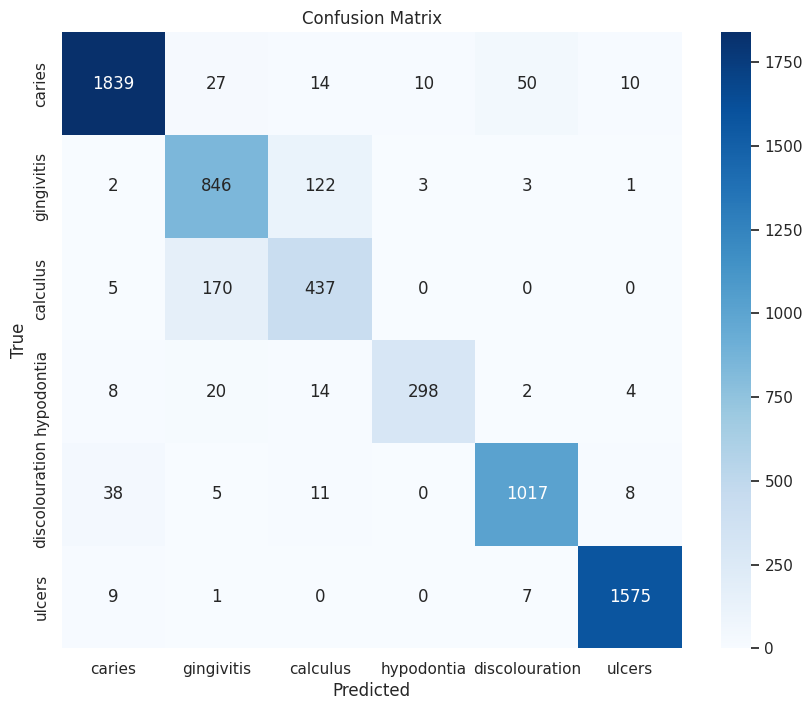

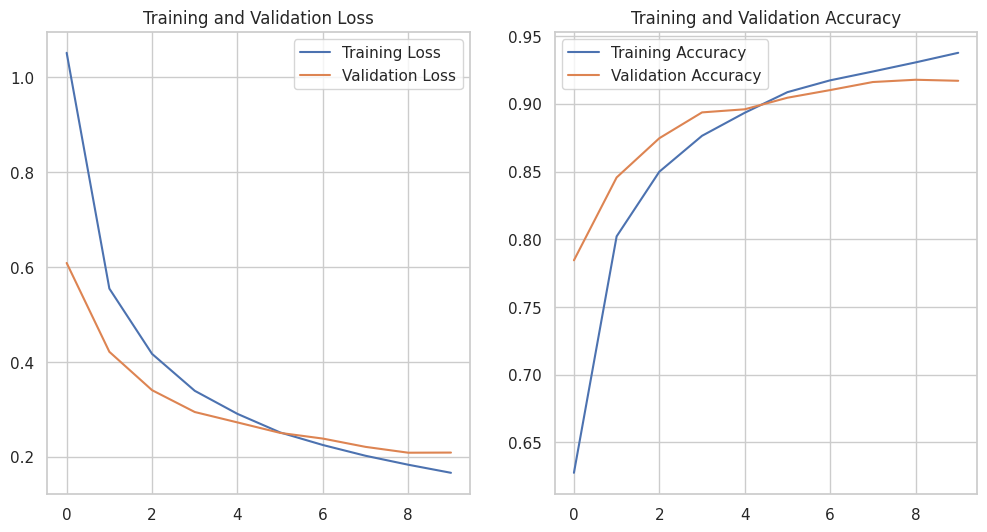

In [ ]:
# Evaluation
model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

# Metrics
accuracy = accuracy_score(y_true, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro')

# Classification Report
report = classification_report(y_true, y_pred, target_names=train_dataset.dataset.classes)
print(report)

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', xticklabels=train_dataset.dataset.classes, yticklabels=train_dataset.dataset.classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.savefig('confusion_matrix.png')
plt.show()

# Accuracy and Loss Graphs
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

plt.savefig('accuracy_loss_graph.png')
plt.show()

# Save Metrics to CSV
metrics_data = {
    'Model': 'enhanceddentalclassifier',
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1 Score': f1,
    'Loss': val_losses[-1]
}
metrics_df = pd.DataFrame([metrics_data])
metrics_df.to_csv('model_performance_metrics.csv', index=False)

In [ ]:
# Save the model
torch.save(model.state_dict(), 'oral_disease_classifier.pth')

<ipython-input-40-b40f2505b6d8>:11: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_model.pth'))
/usr/local/lib/python3.11/dist-packages

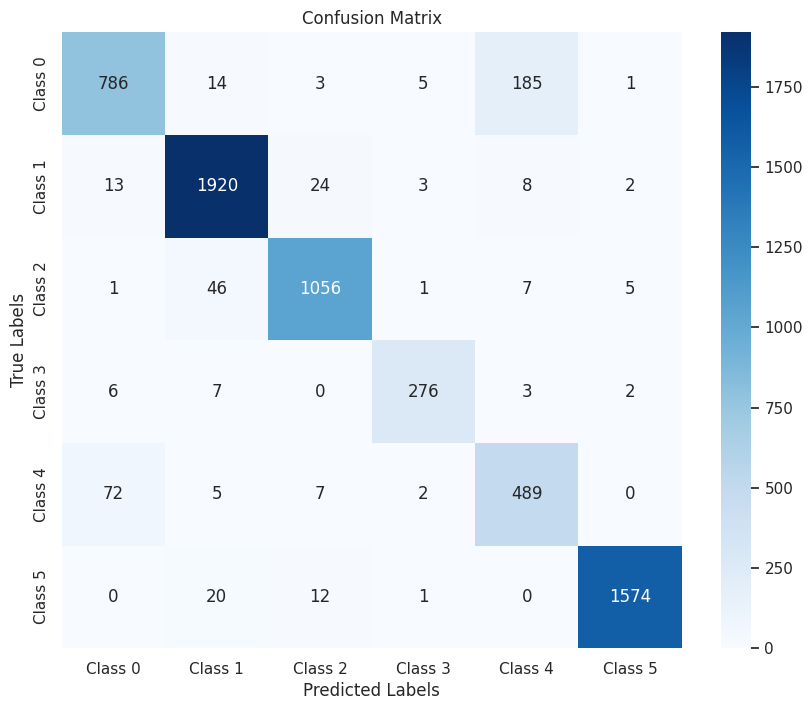

              precision    recall  f1-score      support
Class 0        0.895216  0.790744  0.839744   994.000000
Class 1        0.954274  0.974619  0.964340  1970.000000
Class 2        0.958258  0.946237  0.952209  1116.000000
Class 3        0.958333  0.938776  0.948454   294.000000
Class 4        0.706647  0.850435  0.771902   575.000000
Class 5        0.993687  0.979465  0.986525  1607.000000
accuracy       0.930598  0.930598  0.930598     0.930598
macro avg      0.911069  0.913379  0.910529  6556.000000
weighted avg   0.934123  0.930598  0.931231  6556.000000


In [ ]:
import torch
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Assuming `model` is already defined and loaded with 'best_model.pth'
# Assuming `val_loader` is the DataLoader for the validation dataset

# Load the best model
model.load_state_dict(torch.load('best_model.pth'))
model.eval()

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

# Initialize lists to store true and predicted labels
true_labels = []
predicted_labels = []

# Iterate through the validation dataset
with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        true_labels.extend(labels.cpu().numpy())
        predicted_labels.extend(preds.cpu().numpy())

# Compute the confusion matrix
conf_matrix = confusion_matrix(true_labels, predicted_labels)

# Plot confusion matrix using seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Class 0", "Class 1", "Class 2", "Class 3", "Class 4", "Class 5"],
            yticklabels=["Class 0", "Class 1", "Class 2", "Class 3", "Class 4", "Class 5"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

from sklearn.metrics import classification_report, accuracy_score
import pandas as pd

# Generate classification report
report = classification_report(true_labels, predicted_labels, target_names=["Class 0", "Class 1", "Class 2", "Class 3", "Class 4", "Class 5"], output_dict=True)

# Convert to a DataFrame for better visualization
report_df = pd.DataFrame(report).transpose()

# Display the table with precision, recall, f1-score, and support
print(report_df)

# Save as a CSV or display in a styled format (if needed)
report_df.to_csv("classification_report.csv")

In [ ]:
# Define the original directories and their corresponding class names
original_dirs = {
    'Calculus': '/content/btp_dataset/Calculus',
    'Caries': '/content/btp_dataset/caries',
    'Gingivitis': '/content/btp_dataset/Gingivitis',
    'Ulcers': '/content/btp_dataset/ulcer',
    'Tooth Discoloration': '/content/btp_dataset/discolouration',
    'Hypodontia': '/content/btp_dataset/hypodontia'
}
from sklearn.model_selection import train_test_split


# Define the target base directory
base_dir = '/content/btp_dataset_gradcam'

# Define the target structure
splits = ['train', 'val', 'test']
classes = list(original_dirs.keys())

# Create target directories
for split in splits:
    for class_name in classes:
        os.makedirs(os.path.join(base_dir, split, class_name), exist_ok=True)

# Initialize dictionaries to hold the counts for train, val, and test sets
class_split_counts = {class_name: {'train': 0, 'val': 0, 'test': 0} for class_name in classes}

# Function to copy images to the target directory and count them
def copy_and_count_images(class_name, image_paths):
    # Split the data
    train_paths, test_paths = train_test_split(image_paths, test_size=0.1, random_state=42)
    train_paths, val_paths = train_test_split(train_paths, test_size=0.2, random_state=42)  # 0.2 * 0.9 = 0.18

    # Define split mappings
    split_paths = {
        'train': train_paths,
        'val': val_paths,
        'test': test_paths
    }

    # Copy images to their respective directories and count them
    for split, paths in split_paths.items():
        class_split_counts[class_name][split] = len(paths)
        for img_path in paths:
            target_path = os.path.join(base_dir, split, class_name, os.path.basename(img_path))
            shutil.copy(img_path, target_path)

# Traverse the original directories and gather image paths
for class_name, original_dir in original_dirs.items():
    image_paths = []
    for root, dirs, files in os.walk(original_dir):
        image_paths.extend([os.path.join(root, file) for file in files if file.endswith(('.jpg', '.jpeg', '.png'))])
    if image_paths:
        copy_and_count_images(class_name, image_paths)

print("Images have been copied and organized successfully.")

Images have been copied and organized successfully.


In [ ]:
import os
import shutil
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import precision_recall_curve, average_precision_score

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, random_split
from torchvision.models import resnet18

In [ ]:
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

# Parameters
image_size = (128, 128)
batch_size = 16
num_epochs = 50

# Data augmentation and normalization for training
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(image_size, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# Normalization for validation and testing
val_transforms = transforms.Compose([
    transforms.Resize(image_size),
    transforms.CenterCrop(image_size),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# Load datasets
train_dataset = ImageFolder(train_dir, transform=train_transforms)
val_dataset = ImageFolder(val_dir, transform=val_transforms)
test_dataset = ImageFolder(test_dir, transform=val_transforms)

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=4)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4)

/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [ ]:
num_classes = len(train_dataset.classes)

# Use a smaller model - ResNet18
class CustomModel(nn.Module):
    def __init__(self):
        super(CustomModel, self).__init__()
        self.model = resnet18(weights=True)
        self.model.fc = nn.Linear(self.model.fc.in_features, num_classes)

    def forward(self, x):
        return self.model(x)

# Initialize the model, loss function, and optimizer
model = CustomModel()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 150MB/s]


In [ ]:
os.environ["OMP_NUM_THREADS"] = "1"

# Define the scheduler
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=2, verbose=True)

# Early stopping parameters
early_stopping = True
patience = 3  # Number of epochs to wait if no improvement is observed

# Initialize early stopping variables
best_val_loss = float('inf')
epochs_no_improve = 0
early_stop = False

# Initialize lists to store losses, accuracies, and learning rates
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

# Variables to store y_true and y_scores for precision-recall calculation
y_true = []
y_scores = []

# Training loop
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for i, (inputs, labels) in enumerate(train_loader):
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_dataset)
    epoch_acc = correct / total
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_acc)

    # Validation
    model.eval()
    val_loss = 0.0
    val_preds = []
    val_true = []
    val_outputs = []
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            val_preds.extend(predicted.cpu().numpy())
            val_true.extend(labels.cpu().numpy())
            val_outputs.extend(outputs.cpu().numpy())

    val_loss = val_loss / len(val_dataset)
    val_acc = accuracy_score(val_true, val_preds)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    # Append true labels and predicted scores for precision-recall calculation
    y_true.extend(val_true)
    y_scores.extend(val_outputs)

    print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {epoch_loss:.4f}, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}')

    # Check for improvement in validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        # Save the model checkpoint here if you want

    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f'Early stopping after {epoch+1} epochs.')
            early_stop = True
            break

    # LR scheduler step based on validation loss
    scheduler.step(val_loss)

    if early_stop:
        break

/usr/local/lib/python3.10/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


In [ ]:
!pip install lime


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 6.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=5f194d1584112286ce28435ac6468c894864dd31e230e0b1ca1ce3a3812a271a
  Stored in directory: /root/.cache/pip/wheels/85/fa/a3/9c2d44c9f3cd77cf4e533b58900b2bf4487f2a17e8ec212a3d
Successfully built lime


In [ ]:
!pip install lime


/usr/local/lib/python3.11/dist-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(
<ipython-input-43-794a686fa878>:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you st

FileNotFoundError: [Errno 2] No such file or directory: '/content/btp_dataset_new/validation/random_image.jpg'

<ipython-input-45-a32911a9ae11>:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_model.pth'))


  0%|          | 0/1000 [00:00<?, ?it/s]

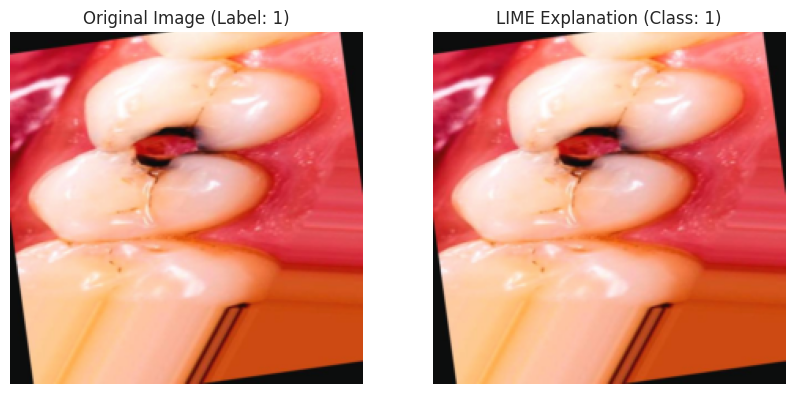

In [ ]:
import torch
import torchvision.transforms as transforms
from lime import lime_image
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Load the best model
model = EnhancedDentalClassifier(num_classes=6)  # Ensure this matches your architecture
model.load_state_dict(torch.load('best_model.pth'))
model.eval()

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

# Define preprocessing transformations (same as used during training)
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),  # Convert PIL image to PyTorch tensor
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Function to convert the model output to probabilities (for LIME)
def predict_fn(images):
    # Convert images to PyTorch tensors and normalize them
    images = torch.stack([preprocess(Image.fromarray(image)) for image in images]).to(device)
    outputs = model(images)
    probabilities = torch.nn.functional.softmax(outputs, dim=1).detach().cpu().numpy()
    return probabilities

# Extract a random image from val_loader
images, labels = next(iter(val_loader))  # Get a batch of images and labels from val_loader
idx = np.random.randint(0, len(images))  # Select a random index from the batch
image_tensor = images[idx]
label = labels[idx].item()

# Convert the PyTorch tensor to a NumPy array for LIME processing
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
image_np = image_tensor.permute(1, 2, 0).numpy() * std + mean  # Undo normalization for visualization
image_np = np.clip(image_np * 255, 0, 255).astype(np.uint8)  # Convert to [0, 255] range

# Initialize LIME explainer
explainer = lime_image.LimeImageExplainer()

# Explain the model's prediction on the selected image
explanation = explainer.explain_instance(
    image_np,
    predict_fn,
    top_labels=3,  # Number of top labels to explain
    hide_color=0,
    num_samples=1000  # Number of perturbed samples to generate
)

# Visualize the explanation for the top label
top_label = explanation.top_labels[0]
temp, mask = explanation.get_image_and_mask(
    top_label,
    positive_only=True,
    num_features=5,
    hide_rest=False
)

# Plot the original image and LIME explanation
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_np)
plt.title(f"Original Image (Label: {label})")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(temp)
plt.title(f"LIME Explanation (Class: {top_label})")
plt.axis("off")
plt.show()


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image

# Load the best model
model = EnhancedDentalClassifier(num_classes=6)  # Ensure this matches your architecture
model.load_state_dict(torch.load('best_model.pth'))
model.eval()

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

# Function to generate Grad-CAM heatmap
def generate_grad_cam(model, image_tensor, target_class=None, device='cuda'):
    # Create a feature extractor to get the output of the last convolutional layer
    # For this architecture, we'll use the output of the FPN
    features = []
    def hook_fn(module, input, output):
        features.append(output.detach())

    # Register the hook on the FPN output
    hook = model.fpn.conv3.register_forward_hook(hook_fn)

    # Forward pass
    model.eval()
    image_tensor = image_tensor.unsqueeze(0).to(device)  # Add batch dimension
    output = model(image_tensor)

    # If target class is not specified, use the predicted class
    if target_class is None:
        target_class = output.argmax(dim=1).item()

    # Backward pass to get gradients
    model.zero_grad()
    class_score = output[0, target_class]
    class_score.backward()

    # Get gradients and activations
    gradients = model.fpn.conv3.weight.grad.detach().cpu()
    activations = features[0].detach().cpu()

    # Remove the hook
    hook.remove()

    # Calculate weights based on global average pooling of gradients
    weights = gradients.mean(dim=[0, 2, 3], keepdim=True)

    # Create heatmap by weighted sum of activation maps
    heatmap = torch.sum(weights * activations, dim=1).squeeze()
    heatmap = np.maximum(heatmap.numpy(), 0)  # ReLU

    # Normalize heatmap
    if np.max(heatmap) > 0:
        heatmap = heatmap / np.max(heatmap)

    # Resize heatmap to match input image size
    heatmap = cv2.resize(heatmap, (224, 224))

    return heatmap, target_class

# Function to overlay heatmap on original image
def overlay_heatmap(image_tensor, heatmap, alpha=0.5):
    # Convert tensor to numpy array and denormalize
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    image = image_tensor.permute(1, 2, 0).numpy() * std + mean
    image = np.clip(image, 0, 1)

    # Convert heatmap to RGB
    heatmap_rgb = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
    heatmap_rgb = cv2.cvtColor(heatmap_rgb, cv2.COLOR_BGR2RGB) / 255.0

    # Overlay heatmap on original image
    overlay = image * (1 - alpha) + heatmap_rgb * alpha
    overlay = np.clip(overlay, 0, 1)

    return image, overlay

# Get a batch of images from the validation loader
images, labels = next(iter(val_loader))

# Select a random image from the batch
idx = np.random.randint(0, len(images))
image_tensor = images[idx].to(device)
true_label = labels[idx].item()

# Generate Grad-CAM heatmap
heatmap, pred_class = generate_grad_cam(model, image_tensor, target_class=None, device=device)

# Overlay heatmap on original image
original_image, overlay_image = overlay_heatmap(image_tensor.cpu(), heatmap)

# Display the results
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title(f"Original Image\nTrue Label: {true_label}")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap='jet')
plt.title(f"Grad-CAM Heatmap\nPredicted Class: {pred_class}")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(overlay_image)
plt.title("Overlay")
plt.axis('off')

plt.tight_layout()
plt.show()

# To visualize multiple images
def visualize_multiple_images(model, val_loader, num_images=5, device='cuda'):
    # Get a batch of images
    images, labels = next(iter(val_loader))

    # Ensure we don't try to display more images than we have
    num_images = min(num_images, len(images))

    for i in range(num_images):
        image_tensor = images[i].to(device)
        true_label = labels[i].item()

        # Generate Grad-CAM heatmap
        heatmap, pred_class = generate_grad_cam(model, image_tensor, target_class=None, device=device)

        # Overlay heatmap on original image
        original_image, overlay_image = overlay_heatmap(image_tensor.cpu(), heatmap)

        # Display the results
        plt.figure(figsize=(12, 4))

        plt.subplot(1, 3, 1)
        plt.imshow(original_image)
        plt.title(f"Original Image\nTrue Label: {true_label}")
        plt.axis('off')

        plt.subplot(1, 3, 2)
        plt.imshow(heatmap, cmap='jet')
        plt.title(f"Grad-CAM Heatmap\nPredicted Class: {pred_class}")
        plt.axis('off')

        plt.subplot(1, 3, 3)
        plt.imshow(overlay_image)
        plt.title("Overlay")
        plt.axis('off')

        plt.tight_layout()
        plt.show()

# Visualize multiple images
visualize_multiple_images(model, val_loader, num_images=3, device=device)


/usr/local/lib/python3.11/dist-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(
<ipython-input-47-7821ce341142>:9: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you sta

RuntimeError: The size of tensor a (256) must match the size of tensor b (512) at non-singleton dimension 1

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Load the best model
model = EnhancedDentalClassifier(num_classes=6)
model.load_state_dict(torch.load('best_model.pth'))
model.eval()

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

# Function to generate Grad-CAM heatmap
def generate_grad_cam(model, image_tensor, target_class=None, device='cuda'):
    # Create a feature extractor to get the output of the FPN
    features = []
    def hook_fn(module, input, output):
        features.append(output.detach())

    # Register the hook on the FPN output (conv3 outputs 512 channels)
    hook = model.fpn.conv3.register_forward_hook(hook_fn)

    # Forward pass
    model.eval()
    image_tensor = image_tensor.unsqueeze(0).to(device)  # Add batch dimension
    output = model(image_tensor)

    # If target class is not specified, use the predicted class
    if target_class is None:
        target_class = output.argmax(dim=1).item()

    # Backward pass to get gradients
    model.zero_grad()
    class_score = output[0, target_class]
    class_score.backward()

    # Get activations from the hook
    activations = features[0]

    # Get gradients flowing back to the FPN
    gradients = torch.autograd.grad(class_score, activations,
                                   retain_graph=True, create_graph=False)[0]

    # Remove the hook
    hook.remove()

    # Global average pooling of gradients
    weights = gradients.mean(dim=(2, 3), keepdim=True)

    # Create heatmap by weighted sum of activation maps
    heatmap = (weights * activations).sum(dim=1).squeeze().cpu()
    heatmap = np.maximum(heatmap.detach().numpy(), 0)  # ReLU

    # Normalize heatmap
    if np.max(heatmap) > 0:
        heatmap = heatmap / np.max(heatmap)

    # Resize heatmap to match input image size
    heatmap = cv2.resize(heatmap, (224, 224))

    return heatmap, target_class

# Function to overlay heatmap on original image
def overlay_heatmap(image_tensor, heatmap, alpha=0.5):
    # Convert tensor to numpy array and denormalize
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    image = image_tensor.permute(1, 2, 0).cpu().numpy() * std + mean
    image = np.clip(image, 0, 1)

    # Convert heatmap to RGB
    heatmap_rgb = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
    heatmap_rgb = cv2.cvtColor(heatmap_rgb, cv2.COLOR_BGR2RGB) / 255.0

    # Overlay heatmap on original image
    overlay = image * (1 - alpha) + heatmap_rgb * alpha
    overlay = np.clip(overlay, 0, 1)

    return image, overlay

# Get a batch of images from the validation loader
images, labels = next(iter(val_loader))

# Select a random image from the batch
idx = np.random.randint(0, len(images))
image_tensor = images[idx].to(device)
true_label = labels[idx].item()

# Generate Grad-CAM heatmap
heatmap, pred_class = generate_grad_cam(model, image_tensor, target_class=None, device=device)

# Overlay heatmap on original image
original_image, overlay_image = overlay_heatmap(image_tensor, heatmap)

# Display the results
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title(f"Original Image\nTrue Label: {true_label}")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap='jet')
plt.title(f"Grad-CAM Heatmap\nPredicted Class: {pred_class}")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(overlay_image)
plt.title("Overlay")
plt.axis('off')

plt.tight_layout()
plt.show()

# To visualize multiple images
def visualize_multiple_images(model, val_loader, num_images=5, device='cuda'):
    # Get a batch of images
    images, labels = next(iter(val_loader))

    # Ensure we don't try to display more images than we have
    num_images = min(num_images, len(images))

    for i in range(num_images):
        image_tensor = images[i].to(device)
        true_label = labels[i].item()

        # Generate Grad-CAM heatmap
        heatmap, pred_class = generate_grad_cam(model, image_tensor, target_class=None, device=device)

        # Overlay heatmap on original image
        original_image, overlay_image = overlay_heatmap(image_tensor, heatmap)

        # Display the results
        plt.figure(figsize=(12, 4))

        plt.subplot(1, 3, 1)
        plt.imshow(original_image)
        plt.title(f"Original Image\nTrue Label: {true_label}")
        plt.axis('off')

        plt.subplot(1, 3, 2)
        plt.imshow(heatmap, cmap='jet')
        plt.title(f"Grad-CAM Heatmap\nPredicted Class: {pred_class}")
        plt.axis('off')

        plt.subplot(1, 3, 3)
        plt.imshow(overlay_image)
        plt.title("Overlay")
        plt.axis('off')

        plt.tight_layout()
        plt.show()

# Visualize multiple images
visualize_multiple_images(model, val_loader, num_images=3, device=device)


<ipython-input-48-949000524de5>:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_model.pth'))


RuntimeError: One of the differentiated Tensors does not require grad

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Load the best model
model = EnhancedDentalClassifier(num_classes=6)
model.load_state_dict(torch.load('best_model.pth'))
model.eval()

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

# Function to generate Grad-CAM heatmap
def generate_grad_cam(model, image_tensor, target_class=None, device='cuda'):
    model.eval()
    image_tensor = image_tensor.unsqueeze(0).to(device)  # Add batch dimension

    # Register hook to get activations from the FPN output
    activations = []
    def hook_fn(module, input, output):
        activations.append(output)

    # Register forward hook on the FPN's conv3 layer
    handle = model.fpn.conv3.register_forward_hook(hook_fn)

    # Forward pass with gradient tracking
    image_tensor.requires_grad_()
    output = model(image_tensor)

    # If target class is not specified, use the predicted class
    if target_class is None:
        target_class = output.argmax(dim=1).item()

    # Zero all existing gradients
    model.zero_grad()

    # Target for backprop
    one_hot = torch.zeros_like(output)
    one_hot[0, target_class] = 1

    # Backward pass
    output.backward(gradient=one_hot)

    # Get activations and gradients - ensure they're on the same device
    act = activations[0].to(device)

    # Calculate gradients with respect to activations
    gradients = image_tensor.grad.to(device)

    # Pool gradients across spatial dimensions
    pooled_gradients = torch.mean(gradients, dim=[2, 3])

    # Weight activation maps with gradients (ensure same device)
    weighted_act = act.clone()
    for i in range(act.size(1)):
        weighted_act[:, i, :, :] *= pooled_gradients[:, i].view(pooled_gradients.size(0), 1, 1)

    # Average over channels
    heatmap = torch.mean(weighted_act, dim=1).squeeze().cpu().numpy()

    # ReLU on the heatmap
    heatmap = np.maximum(heatmap, 0)

    # Normalize heatmap
    if np.max(heatmap) > 0:
        heatmap = heatmap / np.max(heatmap)

    # Resize heatmap to match input image size
    heatmap = cv2.resize(heatmap, (224, 224))

    # Remove the hook
    handle.remove()

    return heatmap, target_class

# Function to overlay heatmap on original image
def overlay_heatmap(image_tensor, heatmap, alpha=0.5):
    # Convert tensor to numpy array and denormalize
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    image = image_tensor.permute(1, 2, 0).cpu().numpy() * std + mean
    image = np.clip(image, 0, 1)

    # Convert heatmap to RGB
    heatmap_rgb = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
    heatmap_rgb = cv2.cvtColor(heatmap_rgb, cv2.COLOR_BGR2RGB) / 255.0

    # Overlay heatmap on original image
    overlay = image * (1 - alpha) + heatmap_rgb * alpha
    overlay = np.clip(overlay, 0, 1)

    return image, overlay

# Get a batch of images from the validation loader
images, labels = next(iter(val_loader))

# Select a random image from the batch
idx = np.random.randint(0, len(images))
image_tensor = images[idx].to(device)
true_label = labels[idx].item()

# Generate Grad-CAM heatmap
heatmap, pred_class = generate_grad_cam(model, image_tensor, target_class=None, device=device)

# Overlay heatmap on original image
original_image, overlay_image = overlay_heatmap(image_tensor, heatmap)

# Display the results
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title(f"Original Image\nTrue Label: {true_label}")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap='jet')
plt.title(f"Grad-CAM Heatmap\nPredicted Class: {pred_class}")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(overlay_image)
plt.title("Overlay")
plt.axis('off')

plt.tight_layout()
plt.show()

# To visualize multiple images
def visualize_multiple_images(model, val_loader, num_images=5, device='cuda'):
    # Get a batch of images
    images, labels = next(iter(val_loader))

    # Ensure we don't try to display more images than we have
    num_images = min(num_images, len(images))

    for i in range(num_images):
        image_tensor = images[i].to(device)
        true_label = labels[i].item()

        # Generate Grad-CAM heatmap
        heatmap, pred_class = generate_grad_cam(model, image_tensor, target_class=None, device=device)

        # Overlay heatmap on original image
        original_image, overlay_image = overlay_heatmap(image_tensor, heatmap)

        # Display the results
        plt.figure(figsize=(12, 4))

        plt.subplot(1, 3, 1)
        plt.imshow(original_image)
        plt.title(f"Original Image\nTrue Label: {true_label}")
        plt.axis('off')

        plt.subplot(1, 3, 2)
        plt.imshow(heatmap, cmap='jet')
        plt.title(f"Grad-CAM Heatmap\nPredicted Class: {pred_class}")
        plt.axis('off')

        plt.subplot(1, 3, 3)
        plt.imshow(overlay_image)
        plt.title("Overlay")
        plt.axis('off')

        plt.tight_layout()
        plt.show()

# Visualize multiple images
visualize_multiple_images(model, val_loader, num_images=3, device=device)


<ipython-input-50-c796056cbd07>:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_model.pth'))


IndexError: index 3 is out of bounds for dimension 1 with size 3

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Load the best model
model = EnhancedDentalClassifier(num_classes=6)
model.load_state_dict(torch.load('best_model.pth'))
model.eval()

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

# Function to generate Grad-CAM heatmap targeting MobileNetV2's last layer
def generate_grad_cam(model, image_tensor, target_class=None, device='cuda'):
    model.eval()
    image_tensor = image_tensor.unsqueeze(0).to(device)  # Add batch dimension

    # Register hook to get activations from the last layer of MobileNetV2
    activations = []
    def hook_fn(module, input, output):
        activations.append(output)

    # Register forward hook on the last layer of MobileNetV2
    # The last layer of MobileNetV2 is typically the last block or feature
    handle = model.base_model.blocks[-1].register_forward_hook(hook_fn)

    # Forward pass with gradient tracking
    image_tensor.requires_grad_()
    output = model(image_tensor)

    # If target class is not specified, use the predicted class
    if target_class is None:
        target_class = output.argmax(dim=1).item()

    # Zero all existing gradients
    model.zero_grad()

    # Target for backprop
    one_hot = torch.zeros_like(output)
    one_hot[0, target_class] = 1

    # Backward pass
    output.backward(gradient=one_hot)

    # Get activations and gradients - ensure they're on the same device
    act = activations[0].to(device)

    # Calculate gradients with respect to activations
    gradients = image_tensor.grad.to(device)

    # Pool gradients across spatial dimensions
    pooled_gradients = torch.mean(gradients, dim=[2, 3])

    # Weight activation maps with gradients (ensure same device)
    weighted_act = act.clone()
    for i in range(act.size(1)):
        weighted_act[:, i, :, :] *= pooled_gradients[:, i].view(pooled_gradients.size(0), 1, 1)

    # Average over channels
    heatmap = torch.mean(weighted_act, dim=1).squeeze().cpu().numpy()

    # ReLU on the heatmap
    heatmap = np.maximum(heatmap, 0)

    # Normalize heatmap
    if np.max(heatmap) > 0:
        heatmap = heatmap / np.max(heatmap)

    # Resize heatmap to match input image size
    heatmap = cv2.resize(heatmap, (224, 224))

    # Remove the hook
    handle.remove()

    return heatmap, target_class

# Function to overlay heatmap on original image
def overlay_heatmap(image_tensor, heatmap, alpha=0.5):
    # Convert tensor to numpy array and denormalize
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    image = image_tensor.permute(1, 2, 0).cpu().numpy() * std + mean
    image = np.clip(image, 0, 1)

    # Convert heatmap to RGB
    heatmap_rgb = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
    heatmap_rgb = cv2.cvtColor(heatmap_rgb, cv2.COLOR_BGR2RGB) / 255.0

    # Overlay heatmap on original image
    overlay = image * (1 - alpha) + heatmap_rgb * alpha
    overlay = np.clip(overlay, 0, 1)

    return image, overlay

# Get a batch of images from the validation loader
images, labels = next(iter(val_loader))

# Select a random image from the batch
idx = np.random.randint(0, len(images))
image_tensor = images[idx].to(device)
true_label = labels[idx].item()

# Generate Grad-CAM heatmap
heatmap, pred_class = generate_grad_cam(model, image_tensor, target_class=None, device=device)

# Overlay heatmap on original image
original_image, overlay_image = overlay_heatmap(image_tensor, heatmap)

# Display the results
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title(f"Original Image\nTrue Label: {true_label}")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap='jet')
plt.title(f"Grad-CAM Heatmap\nPredicted Class: {pred_class}")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(overlay_image)
plt.title("Overlay")
plt.axis('off')

plt.tight_layout()
plt.show()

# To visualize multiple images
def visualize_multiple_images(model, val_loader, num_images=5, device='cuda'):
    # Get a batch of images
    images, labels = next(iter(val_loader))

    # Ensure we don't try to display more images than we have
    num_images = min(num_images, len(images))

    for i in range(num_images):
        image_tensor = images[i].to(device)
        true_label = labels[i].item()

        # Generate Grad-CAM heatmap
        heatmap, pred_class = generate_grad_cam(model, image_tensor, target_class=None, device=device)

        # Overlay heatmap on original image
        original_image, overlay_image = overlay_heatmap(image_tensor, heatmap)

        # Display the results
        plt.figure(figsize=(12, 4))

        plt.subplot(1, 3, 1)
        plt.imshow(original_image)
        plt.title(f"Original Image\nTrue Label: {true_label}")
        plt.axis('off')

        plt.subplot(1, 3, 2)
        plt.imshow(heatmap, cmap='jet')
        plt.title(f"Grad-CAM Heatmap\nPredicted Class: {pred_class}")
        plt.axis('off')

        plt.subplot(1, 3, 3)
        plt.imshow(overlay_image)
        plt.title("Overlay")
        plt.axis('off')

        plt.tight_layout()
        plt.show()

# Visualize multiple images
visualize_multiple_images(model, val_loader, num_images=3, device=device)


<ipython-input-52-bc62a8b20de2>:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_model.pth'))


IndexError: index 3 is out of bounds for dimension 1 with size 3

In [ ]:
import os
import shutil
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import precision_recall_curve, average_precision_score

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, random_split
from torchvision.models import resnet18
print('Libraries are installed')

Libraries are installed


In [ ]:
original_dirs = {
    'Calculus': '/content/btp_dataset/Calculus',
    'Caries': '/content/btp_dataset/caries',
    'Gingivitis':'/content/btp_dataset/Gingivitis',
    'Ulcers': '/content/btp_dataset/ulcer',
    'Tooth Discoloration':'/content/btp_dataset/discolouration',
    'Hypodontia': '/content/btp_dataset/hypodontia'
}

# Define the target base directory
base_dir = '/content/btp_dataset'

# Define the target structure
splits = ['train', 'val', 'test']
classes = list(original_dirs.keys())

# Create target directories
for split in splits:
    for class_name in classes:
        os.makedirs(os.path.join(base_dir, split, class_name), exist_ok=True)

# Initialize dictionaries to hold the counts for train, val, and test sets
class_split_counts = {class_name: {'train': 0, 'val': 0, 'test': 0} for class_name in classes}

# Function to copy images to the target directory and count them
def copy_and_count_images(class_name, image_paths):
    # Split the data
    train_paths, test_paths = train_test_split(image_paths, test_size=0.1, random_state=42)
    train_paths, val_paths = train_test_split(train_paths, test_size=0.2, random_state=42)  # 0.2 * 0.9 = 0.18

    # Define split mappings
    split_paths = {
        'train': train_paths,
        'val': val_paths,
        'test': test_paths
    }

    # Copy images to their respective directories and count them
    for split, paths in split_paths.items():
        class_split_counts[class_name][split] = len(paths)
        for img_path in paths:
            target_path = os.path.join(base_dir, split, class_name, os.path.basename(img_path))
            shutil.copy(img_path, target_path)

# Traverse the original directories and gather image paths
for class_name, original_dir in original_dirs.items():
    image_paths = []
    for root, dirs, files in os.walk(original_dir):
        image_paths.extend([os.path.join(root, file) for file in files if file.endswith(('.jpg', '.jpeg', '.png'))])
    if image_paths:
        copy_and_count_images(class_name, image_paths)

print("Images have been copied and organized successfully.")

Images have been copied and organized successfully.


In [ ]:
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

# Parameters
image_size = (128, 128)
batch_size = 16
num_epochs = 10

# Data augmentation and normalization for training
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(image_size, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# Normalization for validation and testing
val_transforms = transforms.Compose([
    transforms.Resize(image_size),
    transforms.CenterCrop(image_size),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# Load datasets
train_dataset = ImageFolder(train_dir, transform=train_transforms)
val_dataset = ImageFolder(val_dir, transform=val_transforms)
test_dataset = ImageFolder(test_dir, transform=val_transforms)

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=4)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4)

In [ ]:
num_classes = len(train_dataset.classes)

# Use a smaller model - ResNet18
class CustomModel(nn.Module):
    def __init__(self):
        super(CustomModel, self).__init__()
        self.model = resnet18(weights=True)
        self.model.fc = nn.Linear(self.model.fc.in_features, num_classes)

    def forward(self, x):
        return self.model(x)

# Initialize the model, loss function, and optimizer
model = CustomModel()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [ ]:
os.environ["OMP_NUM_THREADS"] = "1"

# Define the scheduler
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=2, verbose=True)

# Early stopping parameters
early_stopping = True
patience = 10  # Number of epochs to wait if no improvement is observed

# Initialize early stopping variables
best_val_loss = float('inf')
epochs_no_improve = 0
early_stop = False

# Initialize lists to store losses, accuracies, and learning rates
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

# Variables to store y_true and y_scores for precision-recall calculation
y_true = []
y_scores = []

# Training loop
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for i, (inputs, labels) in enumerate(train_loader):
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_dataset)
    epoch_acc = correct / total
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_acc)

    # Validation
    model.eval()
    val_loss = 0.0
    val_preds = []
    val_true = []
    val_outputs = []
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            val_preds.extend(predicted.cpu().numpy())
            val_true.extend(labels.cpu().numpy())
            val_outputs.extend(outputs.cpu().numpy())

    val_loss = val_loss / len(val_dataset)
    val_acc = accuracy_score(val_true, val_preds)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    # Append true labels and predicted scores for precision-recall calculation
    y_true.extend(val_true)
    y_scores.extend(val_outputs)

    print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {epoch_loss:.4f}, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}')

    # Check for improvement in validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        # Save the model checkpoint here if you want

    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f'Early stopping after {epoch+1} epochs.')
            early_stop = True
            break

    # LR scheduler step based on validation loss
    scheduler.step(val_loss)

    if early_stop:
        break

Epoch [1/10], Train Loss: 0.9062, Val Loss: 0.6493, Val Acc: 0.7400


/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


Epoch [2/10], Train Loss: 0.6238, Val Loss: 0.5774, Val Acc: 0.7828


/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


Epoch [3/10], Train Loss: 0.5132, Val Loss: 0.3966, Val Acc: 0.8475


...

Epoch [8/10], Train Loss: 0.2714, Val Loss: 0.2460, Val Acc: 0.9070


/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


Epoch [9/10], Train Loss: 0.2506, Val Loss: 0.2609, Val Acc: 0.9012


/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


Epoch [10/10], Train Loss: 0.2239, Val Loss: 0.2615, Val Acc: 0.9048


In [ ]:
model.eval()
test_preds = []
test_true = []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs.data, 1)
        test_preds.extend(predicted.cpu().numpy())
        test_true.extend(labels.cpu().numpy())

test_acc = accuracy_score(test_true, test_preds)
print(f'Test Accuracy: {test_acc:.4f}')

/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


Test Accuracy: 0.9081


In [ ]:
!pip install grad-cam -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 56.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 114.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 90.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 54.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 37.9 MB/s 

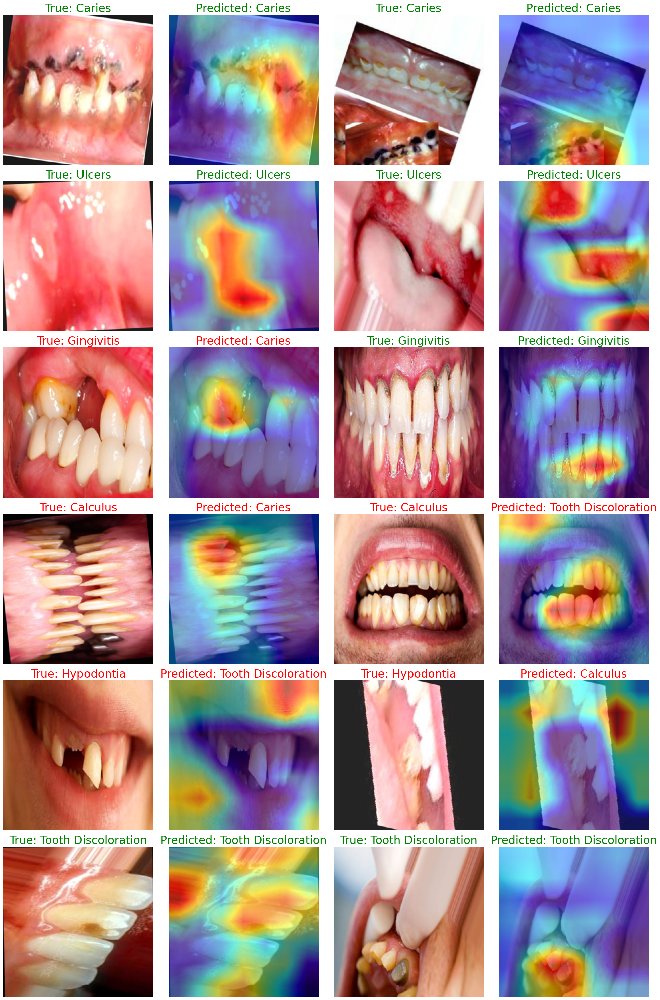

In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

# Set seed for reproducibility
random.seed(42)

def visualize_grad_cam(image_paths, model, device, class_names):

    num_images = len(image_paths)
    num_rows = num_images // 2

    plt.figure(figsize=(20, 5 * num_rows))

    for idx, image_path in enumerate(image_paths):
        # Load and preprocess the image
        input_image = Image.open(image_path).convert('RGB')
        preprocess = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
        input_tensor = preprocess(input_image).unsqueeze(0).to(device)

        # Access the appropriate layer in the model
        target_layer = model.model.layer4[-1]

        # Create an instance of Grad-CAM
        grad_cam = GradCAM(model=model, target_layers=[target_layer])

        # Generate the Grad-CAM
        grayscale_cam = grad_cam(input_tensor=input_tensor)[0]

        # Convert the input image to numpy array and scale to [0, 1]
        input_image_np = np.array(input_image.resize((224, 224))) / 255.0

        # Convert the grayscale cam to an RGB image
        visualization = show_cam_on_image(input_image_np, grayscale_cam, use_rgb=True)

        # Get the predicted class
        model.eval()
        with torch.no_grad():
            outputs = model(input_tensor)
            _, predicted = torch.max(outputs, 1)
            predicted_class = class_names[predicted.item()]

        # Get the true class from the image path
        true_class = os.path.basename(os.path.dirname(image_path))

        # Determine title color based on correct or incorrect prediction
        if true_class == predicted_class:
            title_color = 'green'
        else:
            title_color = 'red'

        # Plot the original image with true class
        plt.subplot(num_rows, 4, 2 * idx + 1)
        plt.imshow(input_image_np)
        plt.title(f'True: {true_class}', fontsize=24, color=title_color)
        plt.axis('off')

        # Plot the Grad-CAM visualization with predicted class
        plt.subplot(num_rows, 4, 2 * idx + 2)
        plt.imshow(visualization)
        plt.title(f'Predicted: {predicted_class}', fontsize=24, color=title_color)
        plt.axis('off')

    plt.tight_layout()
    plt.show()

def get_random_images_from_folders(base_folder, num_images_per_folder=2):
    """
    Gets a specified number of random images from each subfolder.

    Parameters:
    - base_folder (str): The base folder containing subfolders with images.
    - num_images_per_folder (int): Number of random images to select from each subfolder.

    Returns:
    - list of str: List of paths to the randomly selected images.
    """
    image_paths = []
    subfolders = [f.path for f in os.scandir(base_folder) if f.is_dir()]
    for subfolder in subfolders:
        images = [os.path.join(subfolder, f) for f in os.listdir(subfolder) if f.endswith(('.jpg', '.jpeg', '.png'))]
        image_paths.extend(random.sample(images, min(num_images_per_folder, len(images))))
    return image_paths

# Get random images from the test folder
class_names = test_dataset.classes
base_test_folder = '/content/btp_dataset/val'
random_images = get_random_images_from_folders(base_test_folder, num_images_per_folder=2)

# Visualize Grad-CAM for the selected images
visualize_grad_cam(random_images, model, device, class_names)